In [176]:
import pandas as pd
import numpy as np
import sys
import os
import matplotlib.pyplot as plt

In [177]:
d = pd.read_excel(r"E:\aug-2025\Introduction-mms\project-2\cityData\Project 2_Metro Station Survey Data.xlsx",sheet_name="Nagpur")
location = pd.read_csv(r"E:\aug-2025\Introduction-mms\project-2\cityData\nagpur_metro_v2.csv")

Number of null values in 'Metro Station at which the survey is being conducted': 0
Metro Station at which the survey is being conducted
Chhatrapati Square    732
Sitabuldi             701
Kasturchand Park      636
Shankar Nagar         504
Name: count, dtype: int64


<Axes: xlabel='Metro Station at which the survey is being conducted'>

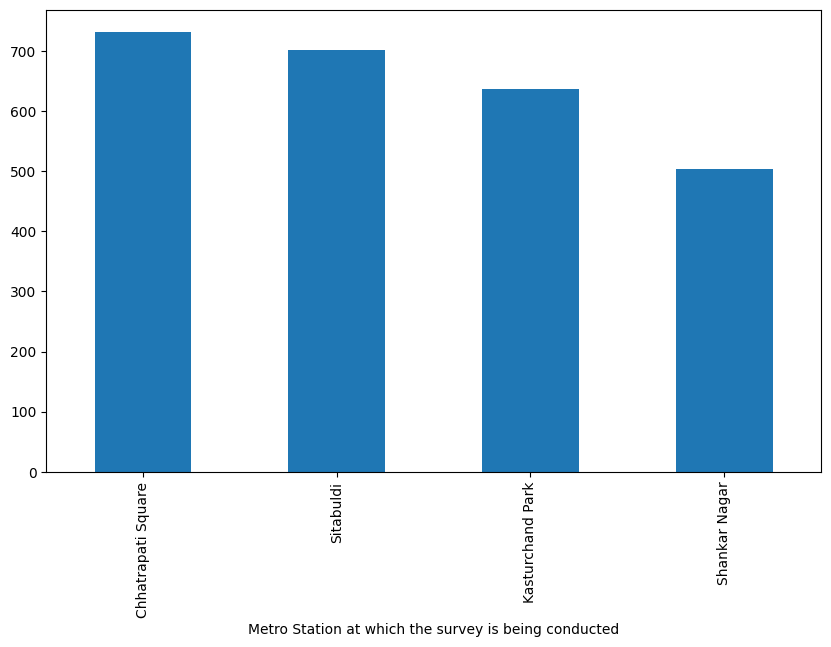

In [178]:
# Metro name at which the survey is being conducted

column_name_metro_name = 'Metro name at which the survey is being conducted'
# Null values in metro station
null_values_metro_station = d[column_name_metro_station].isnull().sum()
print(f"Number of null values in 'Metro Station at which the survey is being conducted': {null_values_metro_station}")

# Value counts in metro station
print(d[column_name_metro_station].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_metro_station].value_counts().plot(kind='bar')

In [179]:
print(location.columns)
location = location[['name', 'Latitude', 'Longitude']]

Index(['full_id', 'osm_id', 'osm_type', 'railway', 'name', 'Latitude',
       'Longitude'],
      dtype='object')


In [180]:
# Location within station where survey is being conducted (example – entry gate/exit gate/platform).
column_name_location_within_station = 'Location within station where survey is being conducted (example – entry gate/exit gate/platform).'

# Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?
column_name_origin_destination = 'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?'


old_names = d[column_name_origin_destination].unique().tolist()
print(len(old_names))
new_names = location['name'].unique().tolist()
print(len(new_names))


# Null values in origin/destination
null_values_origin_destination = d[column_name_origin_destination].isnull().sum()
print(f"Number of null values in 'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?': {null_values_origin_destination}")



# Null values in location
null_values_location = location.isnull().sum().sum()
print(f"Number of null values in location data: {null_values_location}")



import rapidfuzz
from rapidfuzz import process, fuzz

correct_names = location['name'].unique()

def correct_name(wrong):
    match, score, _ = process.extractOne(wrong, correct_names, scorer=fuzz.ratio)
    return match if score > 30 else wrong   # threshold 80% similarity

d[column_name_origin_destination] = d[column_name_origin_destination].apply(correct_name)

print(len(d[column_name_origin_destination].unique().tolist()))
print(location.columns.tolist())
d = d.merge(location, left_on=column_name_origin_destination, right_on='name', how='left')
d.drop(columns=['name'], inplace=True)
d.rename(columns={'Latitude': 'Latitude', 'Longitude': 'Longitude'}, inplace=True)

print(len(d[column_name_origin_destination].unique().tolist()))

print(d['Longitude'].isnull().sum())
print(d['Latitude'].isnull().sum())



23
37
Number of null values in 'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?': 0
Number of null values in location data: 0
23
['name', 'Latitude', 'Longitude']
23
0
0


In [181]:
# Origin and Destination metro station

d['Origin Station'] = d.apply(lambda row: row[column_name_metro_station] if 'Entry Gate' in row[column_name_location_within_station] else row[column_name_origin_destination], axis=1)
d['Destination Station'] = d.apply(lambda row: row[column_name_metro_station] if 'Exit Gate' in row[column_name_location_within_station] else row[column_name_origin_destination], axis=1)



Number of null values in 'Frequency of the trip': 0
['>5 times a week' '3-5 times a week' '1-2 times a week'
 'Travel occasionally every month (<5 times)'
 'Traveling for the first time']
Frequency of the trip
>5 times a week                               1580
3-5 times a week                               798
1-2 times a week                               154
Travel occasionally every month (<5 times)      27
Traveling for the first time                    14
Name: count, dtype: int64


<Axes: xlabel='Frequency of the trip'>

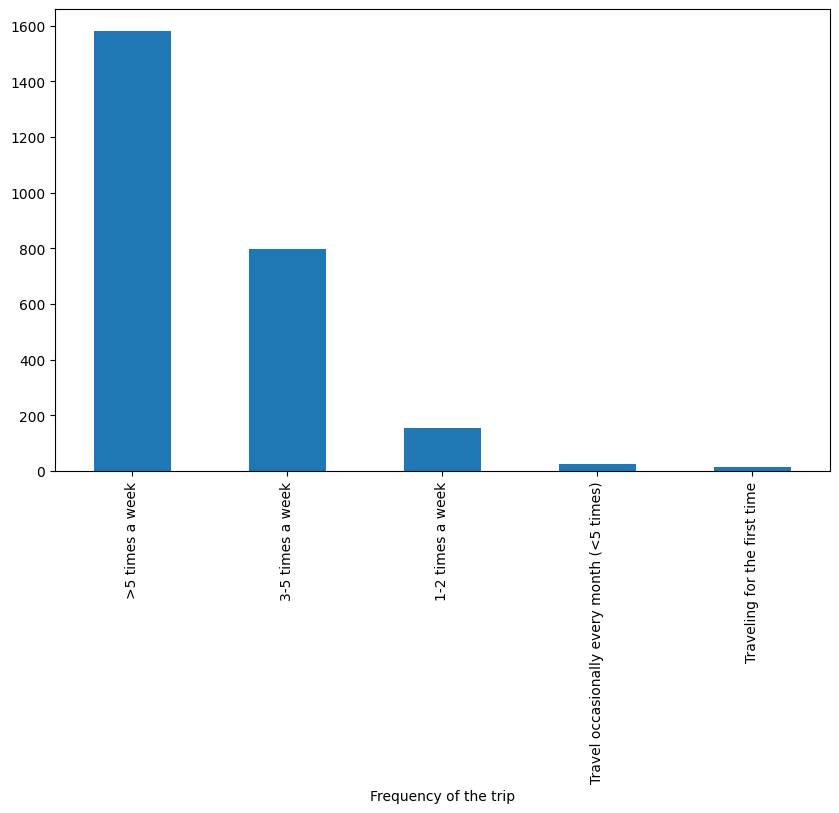

In [182]:
# Frequency of the trip
column_name_frequency_of_trip = 'Frequency of the trip'
# Null values in frequency of trip
null_values_frequency_of_trip = d[column_name_frequency_of_trip].isnull().sum()
print(f"Number of null values in 'Frequency of the trip': {null_values_frequency_of_trip}")

# unique values frequency of trip
print(d[column_name_frequency_of_trip].unique())

# value counts frequency of trip
print(d[column_name_frequency_of_trip].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_frequency_of_trip].value_counts().plot(kind='bar')

Number of null values in 'Purpose of the trip': 0
['Work' 'Educational (visit School, College, etc.)'
 'Recreational (visit movie theatre, shopping mall, etc.)'
 'Shopping (visit supermarket, mandis, shopping mall, etc.)'
 'Social (visit friend, relative, etc.)'
 'Health (visit Hospital, Clinic, etc.)'
 'Transportation Hub (visit Airport, Railway St., Bus Terminus, etc.)']
purpose of this trip
Education    1482
Work          883
Outing        177
Others         31
Name: count, dtype: int64


<Axes: xlabel='purpose of this trip'>

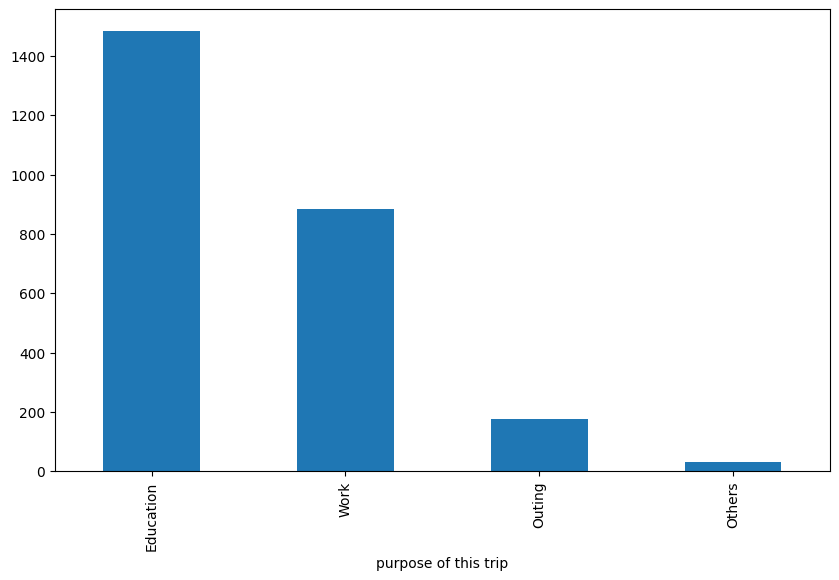

In [183]:
# purpose of this trip
column_name_purpose_of_trip = 'purpose of this trip'
# Null values in purpose of trip
null_values_purpose_of_trip = d[column_name_purpose_of_trip].isnull().sum()
print(f"Number of null values in 'Purpose of the trip': {null_values_purpose_of_trip}")

# unique values purpose of trip
print(d[column_name_purpose_of_trip].unique())

mapping = {'Educational (visit School, College, etc.)': 'Education',
           'Work': 'Work',
           'Social (visit friend, relative, etc.)': 'Outing',
           'Health (visit Hospital, Clinic, etc.)': 'Others',
           'Recreational (visit movie theatre, shopping mall, etc.)': 'Outing',
           'Shopping (visit supermarket, mandis, shopping mall, etc.)': 'Outing',
           'Transportation Hub (visit Airport, Railway St., Bus Terminus, etc.)': 'Others',
           'Any other (please specify)': 'Others'}

d[column_name_purpose_of_trip] = d[column_name_purpose_of_trip].replace(mapping)
# value counts purpose of trip
print(d[column_name_purpose_of_trip].value_counts())

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_purpose_of_trip].value_counts().plot(kind='bar')

Number of null values in 'When do you make the return': 0
['Evening Peak (05:00 PM - 07:59 PM)' 'Morning Peak (08:00 AM - 10:59 AM)'
 'One way trip' 'Evening Off- Peak (08:00 PM - 11:30 PM)'
 'Early Morning (06:00 AM - 07:59 AM)'
 'Morning Off-Peak (11:00 AM - 04:59 PM)']
When do you make the return 
Morning Peak (08:00 AM - 10:59 AM)         1229
Evening Peak (05:00 PM - 07:59 PM)         1029
Evening Off- Peak (08:00 PM - 11:30 PM)     120
Morning Off-Peak (11:00 AM - 04:59 PM)      110
One way trip                                 54
Early Morning (06:00 AM - 07:59 AM)          31
Name: count, dtype: int64


<Axes: xlabel='When do you make the return '>

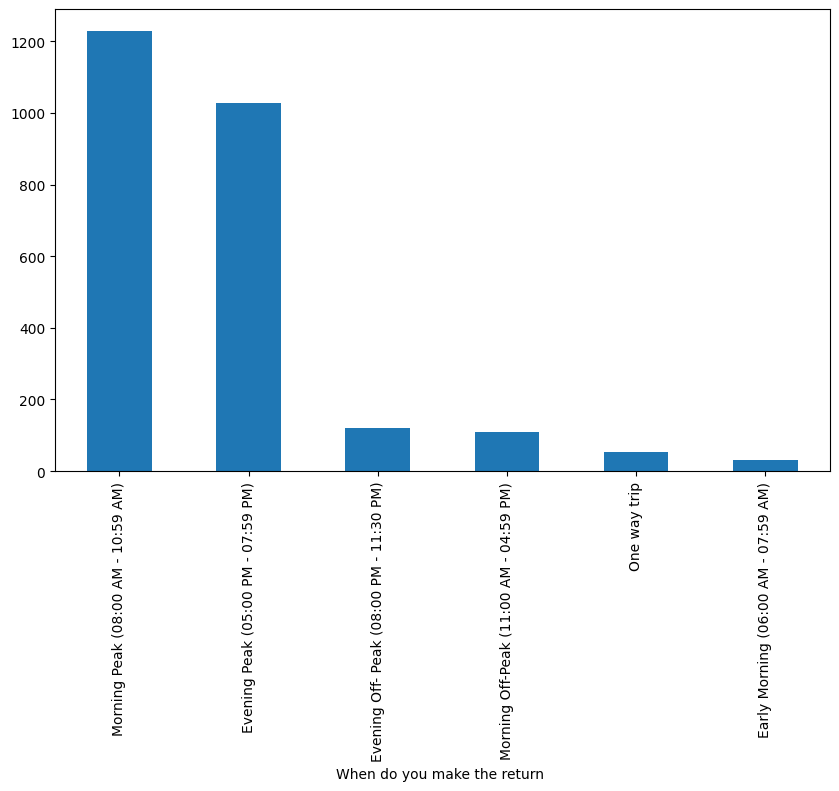

In [184]:
# When do you make the return 
column_name_when_do_you_make_return = 'When do you make the return '
# Null values in when do you make return
null_values_when_do_you_make_return = d[column_name_when_do_you_make_return].isnull().sum()
print(f"Number of null values in 'When do you make the return': {null_values_when_do_you_make_return}")

# unique values when do you make return
print(d[column_name_when_do_you_make_return].unique())
# value counts when do you make return
print(d[column_name_when_do_you_make_return].value_counts())
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_when_do_you_make_return].value_counts().plot(kind='bar')

Number of null values in 'First mile connection (Leg 1)': 0
Unique values in 'First mile connection (Leg 1)': ['Two-wheeler (self-drive)' 'Walk'
 'Somebody picks or drops me (including carpool)' 'Auto (regular)' 'Bus'
 'Cycle' 'Company transport' 'Auto (shared)' 'Suburban train'
 'Four-wheeler (self-drive)']
First mile connection (Leg 1)
Walk              2183
Two-wheeler        169
Others              80
Cycle               74
Auto                47
Bus                 15
Car/Taxi             4
Suburban train       1
Name: count, dtype: int64


<Axes: xlabel='First mile connection (Leg 1)'>

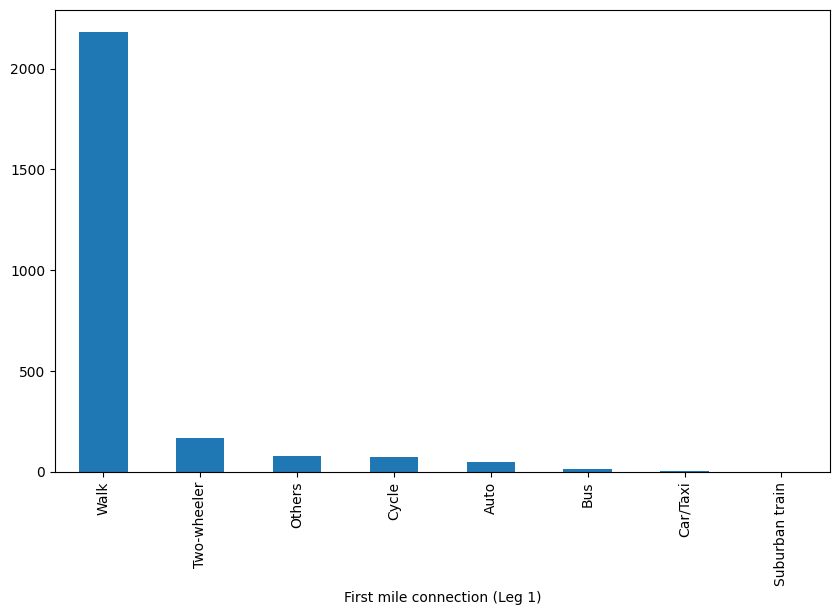

In [185]:
#First mile connection (Leg 1)

column_name_first_mile_leg_1 = 'First mile connection (Leg 1)'
# Null values in first mile leg 1
null_values = d[column_name_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 1)': {null_values}")

# Unique values in first mile leg 1
unique_values_leg_1 = d[column_name_first_mile_leg_1].unique()
print(f"Unique values in 'First mile connection (Leg 1)': {unique_values_leg_1}")

mapping = {
    'Auto': 'Auto',
    'Auto (shared)': 'Auto',
    'Two-wheeler (self-drive)': 'Two-wheeler',
    'Somebody picks or drops me (including carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-wheeler (self-drive)': 'Car/Taxi',
    'Shared taxi': 'Car/Taxi',
    'Walk': 'Walk',
    'E-rickshaw':'Auto',
    'E-auto':'Auto',
    'Auto (regular)': 'Auto',
    'RTV':'Bus',
    'DTC BUS':'Bus',
    'Metro feeder bus':'Bus',
    'Gramin Sewa' : 'Others',
    'Company transport': 'Others',


}

d[column_name_first_mile_leg_1] = d[column_name_first_mile_leg_1].replace(mapping)

# Value counts in first mile leg 1
value_counts = d[column_name_first_mile_leg_1].value_counts()
print(value_counts)

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_first_mile_leg_1].value_counts().plot(kind='bar')

Number of null values in 'First mile connection (Leg 2)': 1524
Number of null values in 'First mile connection (Leg 2)' after filling: 0
['Walk' 'Auto' 'No First mile leg 2' 'Bus' 'Two-wheeler' 'Car/Taxi'
 'Suburban train' 'Others' 'Cycle']
First mile connection (Leg 2)
No First mile leg 2    1524
Auto                    509
Bus                     410
Walk                     83
Cycle                    17
Two-wheeler              11
Others                   11
Car/Taxi                  5
Suburban train            3
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_12260\1325208809.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_First_mile_leg_2].fillna("No First mile leg 2", inplace=True)


<Axes: xlabel='First mile connection (Leg 2)'>

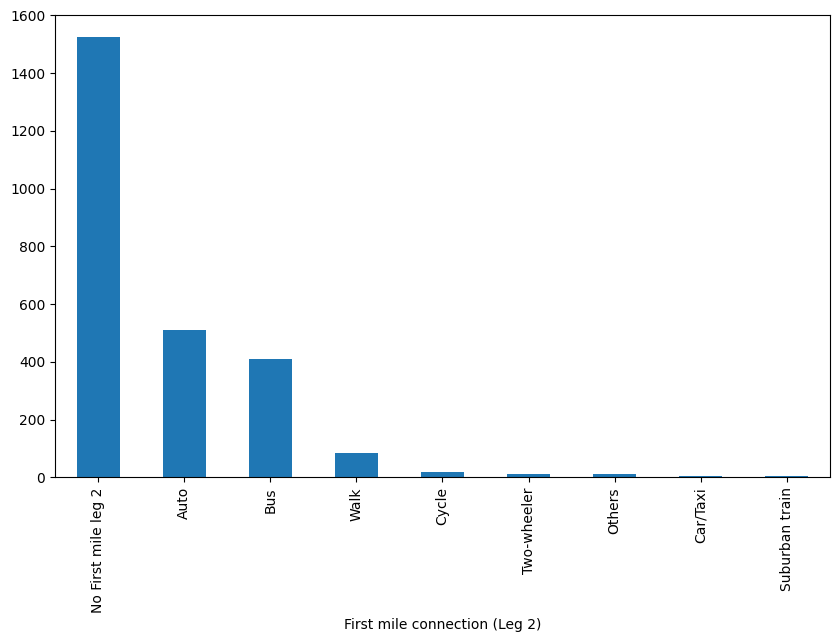

In [186]:
# First mile connection (Leg 2)

column_name_First_mile_leg_2 = 'First mile connection (Leg 2)'

# Null values in first mile leg 2
null_values_leg_2 = d[column_name_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 2)': {null_values_leg_2}")

# Fill Null values
d[column_name_First_mile_leg_2].fillna("No First mile leg 2", inplace=True)

null_values_leg_2_after = d[column_name_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'First mile connection (Leg 2)' after filling: {null_values_leg_2_after}")

mapping = {
    'Auto': 'Auto',
    'Auto (shared)': 'Auto',
    'Two-wheeler (self-drive)': 'Two-wheeler',
    'Somebody picks or drops me (including carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-wheeler (self-drive)': 'Car/Taxi',
    'Shared taxi': 'Car/Taxi',
    'Walk': 'Walk',
    'E-rickshaw':'Auto',
    'E-auto':'Auto',
    'Auto (regular)': 'Auto',
    'RTV':'Bus',
    'DTC BUS':'Bus',
    'Metro feeder bus':'Bus',
    'Gramin Sewa' : 'Others',
    'Company transport': 'Others',
    'No First mile leg 2': 'No First mile leg 2',
    'Regular taxi': 'Car/Taxi',
    'Cycle-rickshaw': 'Cycle',
    'Any Others, Pls Specify': 'Others'
}
d[column_name_First_mile_leg_2] = d[column_name_First_mile_leg_2].replace(mapping)
print(d[column_name_First_mile_leg_2].unique())

# Value counts in first mile leg 2
value_counts_leg_2 = d[column_name_First_mile_leg_2].value_counts()
print(value_counts_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_First_mile_leg_2].value_counts().plot(kind='bar')

Number of null values in 'Primary Mode (Leg 1)': 0
['Metro' 'Walk' 'Bus' 'Auto (shared)' 'Auto (regular)' 'Suburban train']
Primary Mode (Leg 1)
Metro             2192
Walk               374
Auto (shared)        3
Bus                  2
Auto (regular)       1
Suburban train       1
Name: count, dtype: int64


<Axes: xlabel='Primary Mode (Leg 1)'>

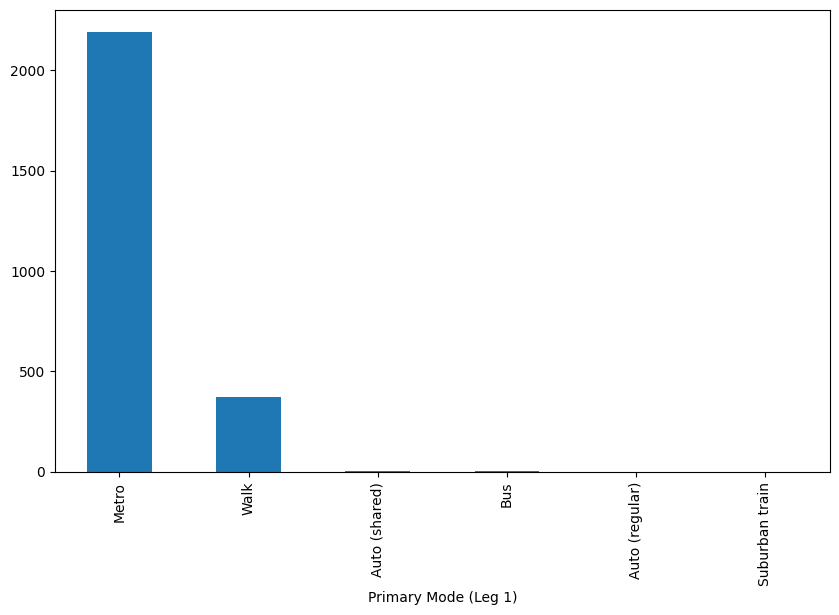

In [187]:
# Primary Mode (Leg 1)

column_name_primary_mode_leg_1 = 'Primary Mode (Leg 1)'

# Null values in primary mode
null_values_primary_mode = d[column_name_primary_mode_leg_1].isnull().sum()
print(f"Number of null values in 'Primary Mode (Leg 1)': {null_values_primary_mode}")

# Unique values in primary mode
print(d[column_name_primary_mode_leg_1].unique())

mapping = {
    'Metro' : 'Metro',
    'DTC BUS' : 'Bus',
    'RTV' : 'Bus',
    'Train' : 'Train',
    'Any Others, Please Specify' : 'Others',
    'Company Transport' : 'Others'
}
d[column_name_primary_mode_leg_1] = d[column_name_primary_mode_leg_1].replace(mapping)

# Value counts in primary mode
value_counts_primary_mode = d[column_name_primary_mode_leg_1].value_counts()
print(value_counts_primary_mode)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_primary_mode_leg_1].value_counts().plot(kind='bar')

Number of null values in 'Primary Mode (Leg 2)': 1960
['No Primary mode leg 2' 'Metro' 'Walk' 'Auto (shared)' 'Cycle' 'Bus'
 'Two-wheeler (self-drive)']
Primary Mode (Leg 2)
No Primary mode leg 2    1960
Metro                     381
Walk                      203
Auto (shared)              17
Bus                         6
Cycle                       4
Two-wheeler                 2
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_12260\3865590819.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_primary_mode_leg_2].fillna("No Primary mode leg 2", inplace=True)


<Axes: xlabel='Primary Mode (Leg 2)'>

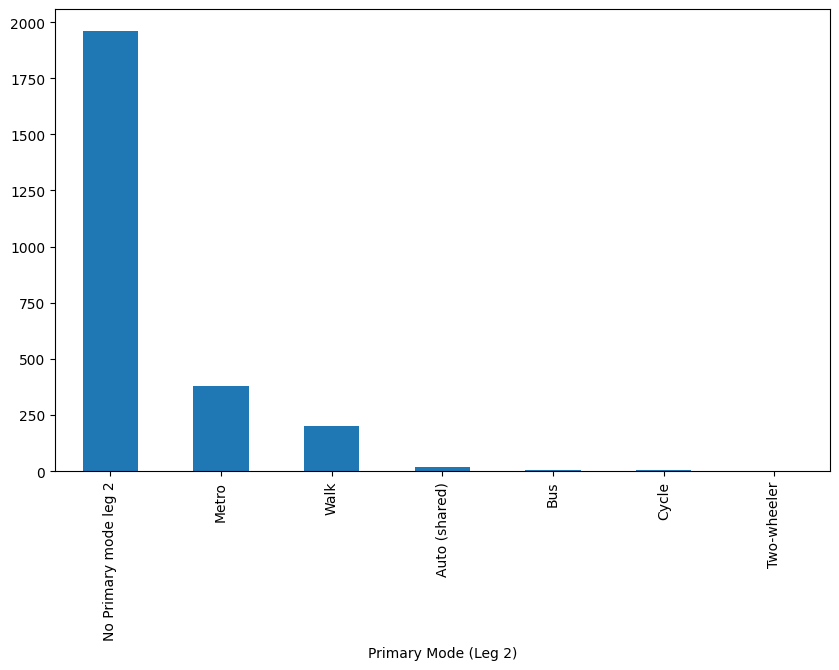

In [188]:
# Primary Mode (Leg 2)
column_name_primary_mode_leg_2 = 'Primary Mode (Leg 2)'

# Null values in primary mode leg 2
null_values_primary_mode_leg_2 = d[column_name_primary_mode_leg_2].isnull().sum()
print(f"Number of null values in 'Primary Mode (Leg 2)': {null_values_primary_mode_leg_2}")


# Replace null values with "No Primary mode leg 2"
d[column_name_primary_mode_leg_2].fillna("No Primary mode leg 2", inplace=True)

# Unique values in primary mode leg 2
print(d[column_name_primary_mode_leg_2].unique())

mapping = {
    'No Primary mode leg 2' : 'No Primary mode leg 2',
    'Metro' : 'Metro',
    'Metro feeder bus' : 'Bus',
    'RTV' : 'Bus',
    'Train' : 'Train',
    'Metro Feeder Bus' : 'Others',
    'Somebody picks or drops me (including carpool)' : 'Others',
    'DTC BUS' : 'Bus',
    'Two-wheeler (self-drive)' : 'Two-wheeler',

}
d[column_name_primary_mode_leg_2] = d[column_name_primary_mode_leg_2].replace(mapping)

# Value counts in primary mode leg 2
value_counts_primary_mode_leg_2 = d[column_name_primary_mode_leg_2].value_counts()
print(value_counts_primary_mode_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_primary_mode_leg_2].value_counts().plot(kind='bar')

Number of null values in 'Last Mile connection (Leg 1)': 74
['Walk' 'Two-wheeler (self-drive)' 'Auto (shared)' 'Auto (regular)'
 'Somebody picks or drops me (including carpool)' 'Bus' 'Cycle'
 'Shared taxi' nan 'Four-wheeler (self-drive)']
Last Mile connection (Leg 1)
Walk           1999
Auto            264
Bus              89
Two-wheeler      64
Cycle            41
Others           38
Car/Taxi          4
Name: count, dtype: int64


<Axes: xlabel='Last Mile connection (Leg 1)'>

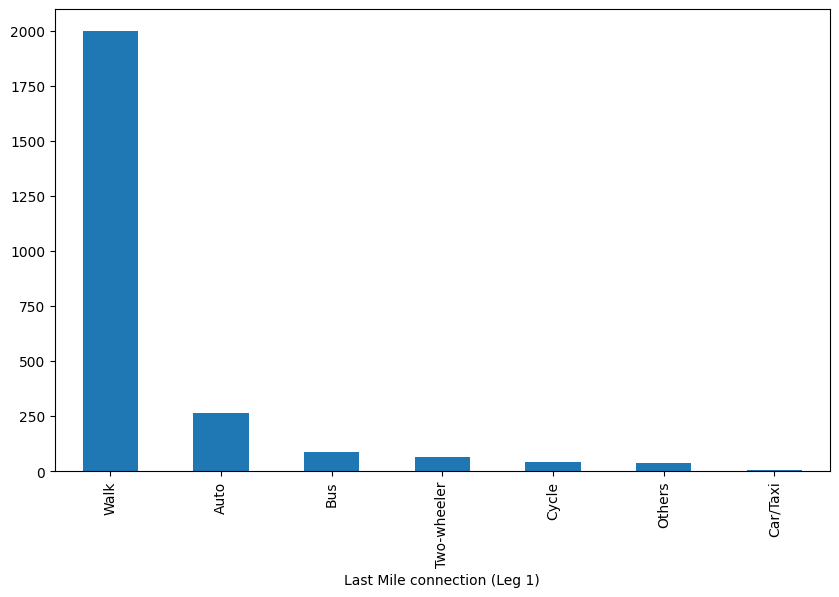

In [ ]:
# Last Mile connection (Leg 1)
column_name_last_mile_leg_1 = 'Last Mile connection (Leg 1)'
# Null values in last mile leg 1
null_values_last_mile_leg_1 = d[column_name_last_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Last Mile connection (Leg 1)': {null_values_last_mile_leg_1}")

# Unique values in last mile leg 1
print(d[column_name_last_mile_leg_1].unique())


mapping = {
    'Auto': 'Auto',
    'Auto (shared)': 'Auto',
    'Two-wheeler (self-drive)': 'Two-wheeler',
    'Somebody picks or drops me (including carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-wheeler (self-drive)': 'Car/Taxi',
    'Shared taxi': 'Car/Taxi',
    'Walk': 'Walk',
    'E-rickshaw':'Auto',
    'E-auto':'Auto',
    'Auto (regular)': 'Auto',
    'RTV':'Bus',
    'DTC BUS':'Bus',
    'Metro feeder bus':'Bus',
    'Gramin Sewa' : 'Others',
    'Company transport': 'Others',
    'No First mile leg 2': 'No First mile leg 2',
    'Regular taxi': 'Car/Taxi',
    'Cycle-rickshaw': 'Cycle',
    'Any Others, Pls Specify': 'Others'
}

d[column_name_last_mile_leg_1] = d[column_name_last_mile_leg_1].replace(mapping)

# Value counts in last mile leg 1
value_counts_last_mile_leg_1 = d[column_name_last_mile_leg_1].value_counts()
print(value_counts_last_mile_leg_1)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_last_mile_leg_1].value_counts().plot(kind='bar')

Number of null values in 'Last Mile connection (Leg 2)': 2252
['No Last mile leg 2' 'Walk' 'Cycle' 'Auto (regular)'
 'Two-wheeler (self-drive)' 'Bus'
 'Somebody picks or drops me (including carpool)' 'Auto (shared)'
 'Shared taxi']
Last Mile connection (Leg 2)
No Last mile leg 2    2252
Walk                   191
Auto                    60
Bus                     58
Others                   4
Two-wheeler              4
Cycle                    3
Car/Taxi                 1
Name: count, dtype: int64


C:\Users\maddi\AppData\Local\Temp\ipykernel_12260\2745994919.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d[column_name_last_mile_leg_2].fillna("No Last mile leg 2", inplace=True)


<Axes: xlabel='Last Mile connection (Leg 2)'>

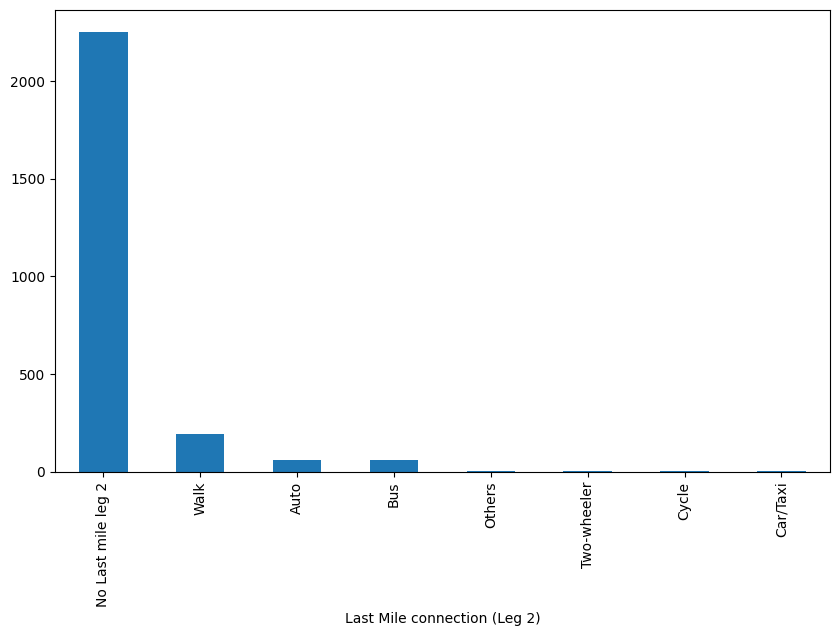

In [190]:
# Last Mile connection (Leg 2)
column_name_last_mile_leg_2 = 'Last Mile connection (Leg 2)'
# Null values in last mile leg 2
null_values_last_mile_leg_2 = d[column_name_last_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Last Mile connection (Leg 2)': {null_values_last_mile_leg_2}")

# Fill Null values
d[column_name_last_mile_leg_2].fillna("No Last mile leg 2", inplace=True)

# Unique values in last mile leg 2
print(d[column_name_last_mile_leg_2].unique())

mapping = {
    'Auto': 'Auto',
    'Auto (shared)': 'Auto',
    'Two-wheeler (self-drive)': 'Two-wheeler',
    'Somebody picks or drops me (including carpool)': 'Others',
    'Cycle': 'Cycle',
    'Auto (Hail-Regular)': 'Auto',
    'Auto (App Based- Ola/ Uber/ Rapido)': 'Auto',
    'Public Bicycle Sharing (App Based- Yulu)': 'Cycle',
    'Two-Wheeler (App Based- Rapido)': 'Two-wheeler',
    'Four-wheeler (self-drive)': 'Car/Taxi',
    'Shared taxi': 'Car/Taxi',
    'Walk': 'Walk',
    'E-rickshaw':'Auto',
    'E-auto':'Auto',
    'Auto (regular)': 'Auto',
    'RTV':'Bus',
    'DTC BUS':'Bus',
    'Metro feeder bus':'Bus',
    'Gramin Sewa' : 'Others',
    'Company transport': 'Others',
    'No First mile leg 2': 'No First mile leg 2',
    'Regular taxi': 'Car/Taxi',
    'Cycle-rickshaw': 'Cycle',
    'Any Others, Pls Specify': 'Others'
}
d[column_name_last_mile_leg_2] = d[column_name_last_mile_leg_2].replace(mapping)
# Value counts in last mile leg 2
value_counts_last_mile_leg_2 = d[column_name_last_mile_leg_2].value_counts()
print(value_counts_last_mile_leg_2)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_last_mile_leg_2].value_counts().plot(kind='bar')

Number of null values in 'How do you usually pay for your Metro journey?': 0
Q15: How do you usually pay for your Metro journey?
Single Ticket                  2278
Smartcard (pay as you like)     288
Mobile application                5
Group Ticket                      2
Name: count, dtype: int64


<Axes: xlabel='Q15: How do you usually pay for your Metro journey?'>

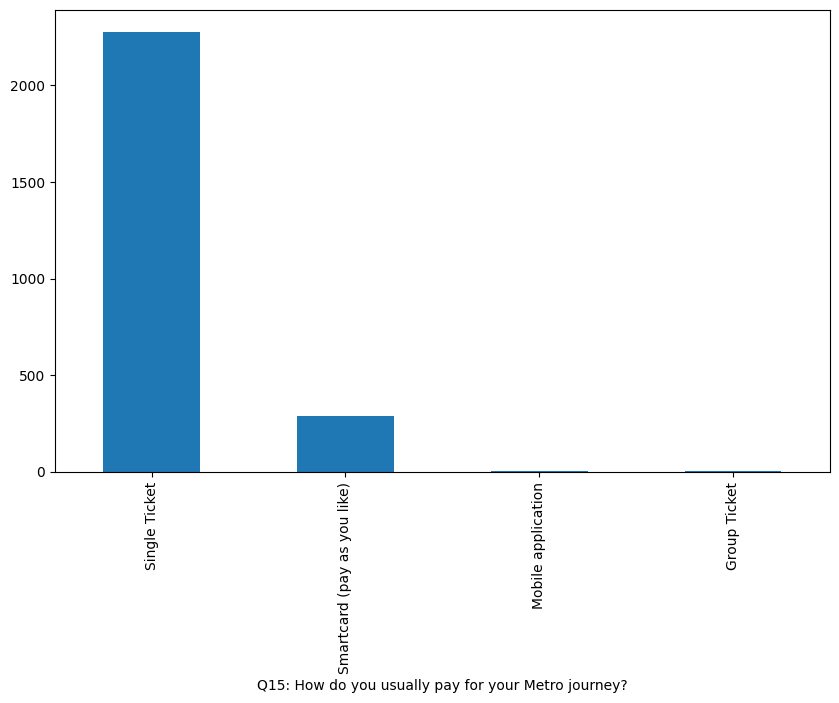

In [191]:
# Q10. How do you usually pay  for your Metro journey?
column_name_payment_method = 'Q15: How do you usually pay for your Metro journey?'
# Null values in payment method
null_values_payment_method = d[column_name_payment_method].isnull().sum()
print(f"Number of null values in 'How do you usually pay for your Metro journey?': {null_values_payment_method}")

mapping = {
    'Smart Card': 'Smart Card',
    'Token': 'Token',
    'Tourist Card 1': 'Tourist Card',
    'Tourist Card 3': 'Tourist Card',
    'Return Ticket':'Single Ticket'
}
d[column_name_payment_method] = d[column_name_payment_method].replace(mapping)

value_counts_payment_method = d[column_name_payment_method].value_counts()
print(value_counts_payment_method)

# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_payment_method].value_counts().plot(kind='bar')

Number of null values in 'Gender': 0
Gender
Male      1478
Female    1095
Name: count, dtype: int64


<Axes: xlabel='Gender'>

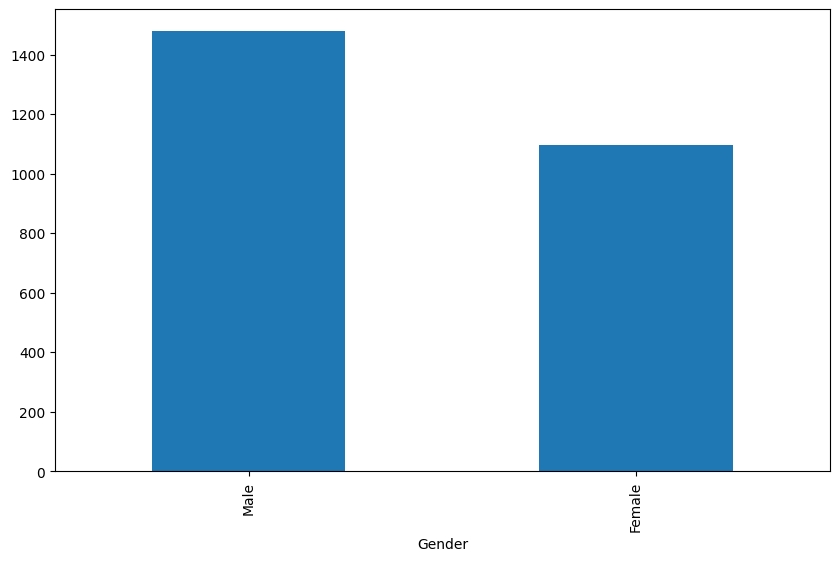

In [192]:
# Gender
column_name_gender = 'Gender'
# Null values in gender
null_values_gender = d[column_name_gender].isnull().sum()
print(f"Number of null values in 'Gender': {null_values_gender}")

# Value counts
value_counts_gender = d[column_name_gender].value_counts()
print(value_counts_gender)
# Graphical representation
plt.figure(figsize=(10,6))
d[column_name_gender].value_counts().plot(kind='bar')

Number of null values in 'Age': 0
['19 - 25' '26 - 35' '36 -50' '51-60' 'Less than 18' '60+']
Age
19 - 25            1760
26 - 35             445
36 -50              227
Less than 18         88
Greater than 50      53
Name: count, dtype: int64


<Axes: xlabel='Age'>

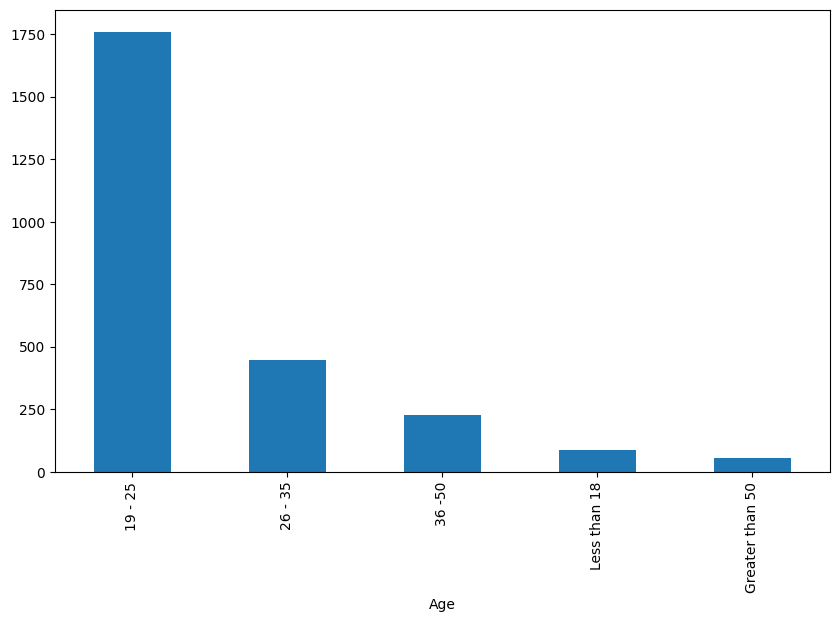

In [193]:
# Age
column_name_age = 'Age'
# Null values in age
null_values_age = d[column_name_age].isnull().sum()
print(f"Number of null values in 'Age': {null_values_age}")
# UNIQUE VALUES
print(d[column_name_age].unique())

mapping = {
    '19 - 25':'19 - 25',
    '26 - 35':'26 - 35',
    '36 - 50':'36 - 50',
    'Refused':'26 - 35',
    'Less Than 18':'Less Than 18',
    '51-60':'Greater than 50',
    '60+':'Greater than 50',
}
d[column_name_age] = d[column_name_age].replace(mapping)

# VALUE COUNTS
value_counts_age = d[column_name_age].value_counts()
print(value_counts_age)

# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_age].value_counts().plot(kind='bar')

Number of null values in 'Educational qualification?': 0
['High school graduate, diploma, or the equivalent (12th pass)'
 "Bachelor's degree" 'Some high school, no diploma (10th pass)'
 "Master's degree" 'Professional degree' 'Some college credit, no degree'
 'Trade/technical/vocational training' 'Doctorate degree'
 'No schooling completed' 'Up to 8th grade']
Educational qualification?
12th Pass        1349
Degree Holder     710
Below 12th        289
Post Graduate     225
Name: count, dtype: int64


<Axes: xlabel='Educational qualification?'>

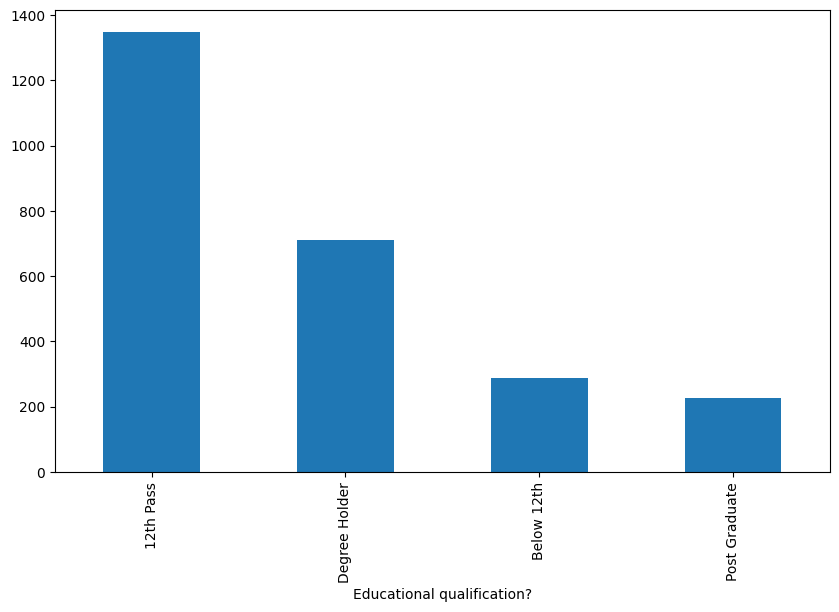

In [194]:
# Educational qualification?
column_name_education = 'Educational qualification?'
# Null values in educational qualification
null_values_education = d[column_name_education].isnull().sum()
print(f"Number of null values in 'Educational qualification?': {null_values_education}")

# UNIQUE VALUES
print(d[column_name_education].unique())

mapping = {
    
    'Some college credit, no degree' : '12th Pass',
    'Professional Degree' : 'Degree Holder',    
    'High school graduate, diploma, or the equivalent (12th pass)' : '12th Pass',
    'Trade/Technical/Vocational Training' : '12th Pass',
    'Up To 8th Grade' : 'Below 12th',
    'Masters Degree' : 'Post Graduate',
    'Doctorate degree' : 'Post Graduate',
    'Some high school, no diploma (10th pass)' : 'Below 12th',
    'No schooling completed' : 'Below 12th',
    'Bachelor’s degree' : 'Degree Holder',
    'Master’s degree' : 'Post Graduate',
    'Trade/technical/vocational training' : 'Post Graduate',
    'Professional degree' : 'Degree Holder',
    'Up to 8th grade': 'Below 12th',
    "Bachelor's degree" : 'Degree Holder',
    "Master's degree": 'Post Graduate',

}

d[column_name_education] = d[column_name_education].replace(mapping)

# VALUE COUNTS
value_counts_education = d[column_name_education].value_counts()
print(value_counts_education)

# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_education].value_counts().plot(kind='bar')


Number of null values in 'Occupation': 0
['A student' 'Employed' 'Out of work and looking for work' 'A homemaker'
 'DAILY WAGE WORKER' 'Self-employed' 'Unable to work' 'Retired' 'Others'
 'Out of work but not currently looking for work']
Occupation
Student              1561
Employed              720
Self-Employed         139
Unemployed             69
Homemaker              43
Daily Wage Worker      26
Retired                10
Others                  5
Name: count, dtype: int64


<Axes: xlabel='Occupation'>

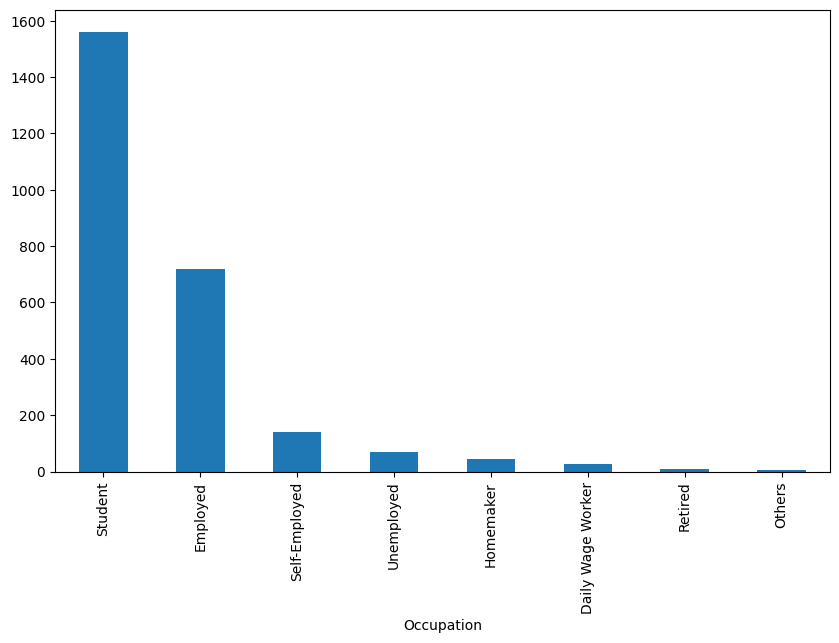

In [195]:
# Occupation

column_name_occupation = 'Occupation'
# Null values in occupation
null_values_occupation = d[column_name_occupation].isnull().sum()
print(f"Number of null values in 'Occupation': {null_values_occupation}")
# UNIQUE VALUES
print(d[column_name_occupation].unique())

mapping = {'A student' : 'Student', 
           'Employed' : 'Employed', 
           'Self-employed' : 'Self-Employed', 
           'A homemaker' : 'Homemaker',
             'Awaiting Job' : 'Unemployed',
           'Unemployed' : 'Unemployed', 
           'DAILY WAGE WORKER' : 'Daily Wage Worker', 
           'Retired' : 'Retired', 
           'Unable to work' : 'Unemployed',
           'Out of work and looking for work': 'Unemployed',
           'Others': 'Others',
           'Out of work but not currently looking for work': 'Unemployed',
           }
d[column_name_occupation] = d[column_name_occupation].replace(mapping)

# VALUE COUNTS
value_counts_occupation = d[column_name_occupation].value_counts()
print(value_counts_occupation)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_occupation].value_counts().plot(kind='bar')

Number of null values in 'Monthly household income': 0
count              2573
unique                9
top       20,001-40,000
freq                852
Name: Monthly household income, dtype: object
['10,001-20,000' '20,001-40,000' '40,001-60,000' '60,001-80,000'
 'Above 1,00,000' '80,001 - 1,00,000' 'Refused' '5,0001 -10,000' '<5k']
Monthly household income
20,001-40,000     1075
10,001-20,000      847
40,001-60,000      297
5,0001 -10,000     160
Above 60,000       150
<5k                 44
Name: count, dtype: int64


<Axes: xlabel='Monthly household income'>

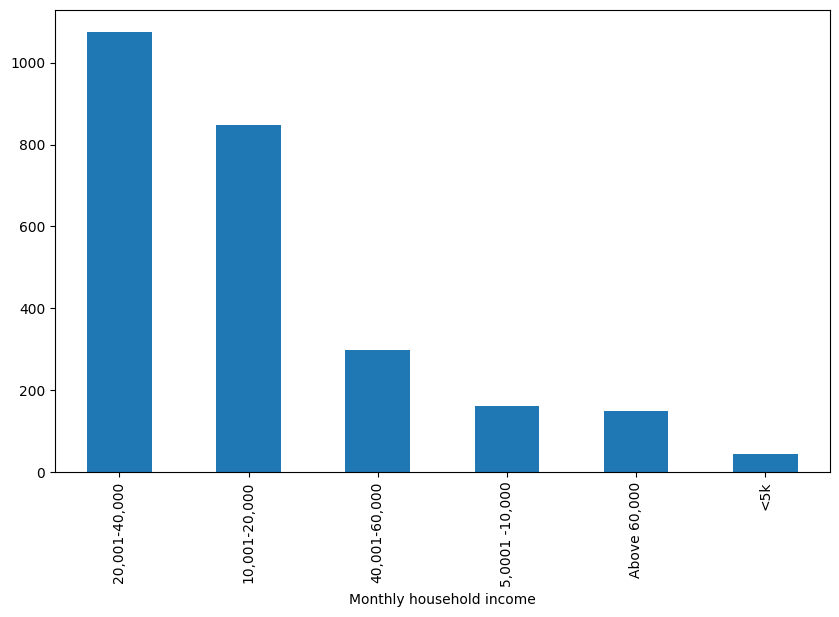

In [196]:
# Monthly household income
column_name_monthly_income = 'Monthly household income'
# Null values in monthly household income
null_values_monthly_income = d[column_name_monthly_income].isnull().sum()
print(f"Number of null values in 'Monthly household income': {null_values_monthly_income}")

print(d[column_name_monthly_income].describe())
# UNIQUE VALUES
print(d[column_name_monthly_income].unique())

mapping = {
    '5,001 -10,000': '5,001-10,000',
    '10,001-20,000': '10,001-20,000',
    '20,001-40,000': '20,001-40,000',
    '40,001-60,000': '40,001-60,000',
    '60,001-80,000': 'Above 60,000',
    '80,001 - 1,00,000': 'Above 60,000',
    'Above 1,00,000': 'Above 60,000',
    'Refused': '20,001-40,000',
    '<5k': '<5k'
}

d[column_name_monthly_income] = d[column_name_monthly_income].replace(mapping)

# VALUE COUNTS
value_counts_monthly_income = d[column_name_monthly_income].value_counts()
print(value_counts_monthly_income)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_monthly_income].value_counts().plot(kind='bar')



In [197]:
# Household members

column_name_household_members = 'Household members'
# Null values in household members
null_values_household_members = d[column_name_household_members].isnull().sum()
print(f"Number of null values in 'Household members': {null_values_household_members}")

unique_values_household_members = d[column_name_household_members].unique()
print(f"Unique values in 'Household members': {unique_values_household_members}")



Number of null values in 'Household members': 0
Unique values in 'Household members': [ 4  5  3  2  8  6 12 15 11  7  9  1 13 14 10 16 41 18]


Number of null values in 'Number of vehicles in the household - 2W:': 0
[1.  2.  0.  4.  3.  5.  6.  8.  0.1]
Number of vehicles in the household - 2W:
One                 1383
Two                  733
Zero                 349
Greater than Two      85
4.0                   23
Name: count, dtype: int64


<Axes: xlabel='Number of vehicles in the household - 2W:'>

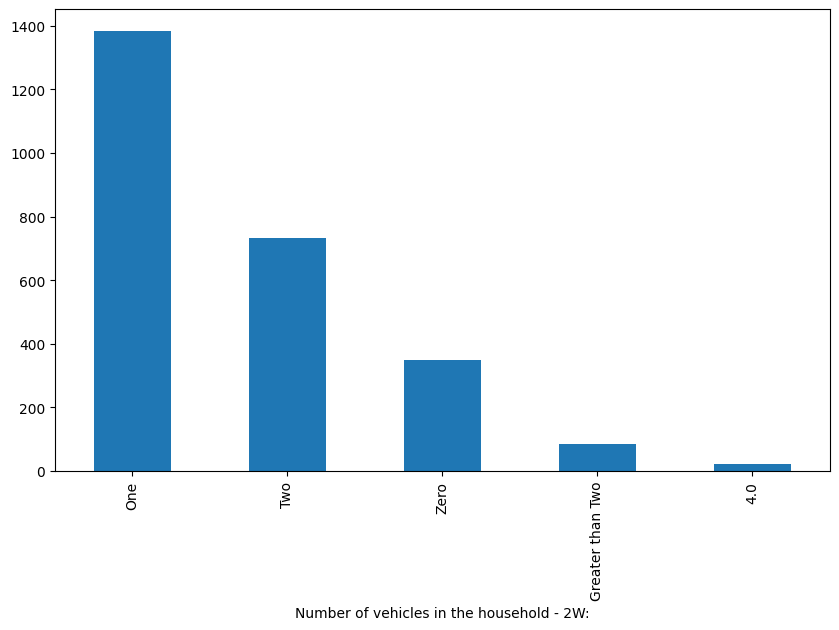

In [198]:
# Number of vehicles in the household - 2W:
column_name_vehicles_2w = 'Number of vehicles in the household - 2W:'
# Null values in 2W vehicles
null_values_vehicles_2w = d[column_name_vehicles_2w].isnull().sum()
print(f"Number of null values in 'Number of vehicles in the household - 2W:': {null_values_vehicles_2w}")

print(d[column_name_vehicles_2w].unique())

mapping = {
    0 : 'Zero'
    , 1 : 'One'
    , 2 : 'Two'
    , 10 : 'Greater than Two'
    , 3. : 'Greater than Two'
    , 8. : 'Greater than Two'
    , 6. : 'Greater than Two'
    , 5. : 'Greater than Two',
     0.1 : 'Zero'
}
d[column_name_vehicles_2w] = d[column_name_vehicles_2w].replace(mapping)


value_counts_vehicles_2w = d[column_name_vehicles_2w].value_counts()
print(value_counts_vehicles_2w)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_vehicles_2w].value_counts().plot(kind='bar')



Number of null values in 'Number of vehicles in the household - 4W': 0
[ 0  1  3  2  9 10]
Number of vehicles in the household - 4W
Zero                2168
One                  363
Two                   33
Greater than Two       9
Name: count, dtype: int64


<Axes: xlabel='Number of vehicles in the household - 4W'>

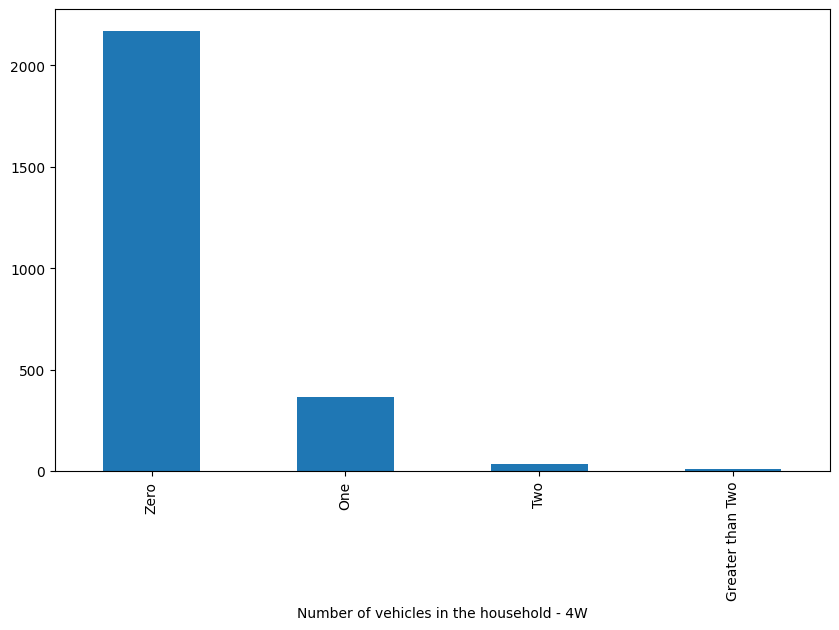

In [199]:
# Number of vehicles in the household - 4W
column_name_vehicles_4w = 'Number of vehicles in the household - 4W'
# Null values in 4W vehicles
null_values_vehicles_4w = d[column_name_vehicles_4w].isnull().sum()
print(f"Number of null values in 'Number of vehicles in the household - 4W': {null_values_vehicles_4w}")
print(d[column_name_vehicles_4w].unique())

mapping = {
    0 : 'Zero'
    , 1 : 'One'
    , 2 : 'Two'
    , 8 : 'Greater than Two'
    , 3 : 'Greater than Two'
    , 4 : 'Greater than Two'
    , 6 : 'Greater than Two',
    9 : 'Greater than Two',
    10 : 'Greater than Two',
}

d[column_name_vehicles_4w] = d[column_name_vehicles_4w].replace(mapping)

# VALUE COUNTS
value_counts_vehicles_4w = d[column_name_vehicles_4w].value_counts()
print(value_counts_vehicles_4w)
# GRAPHICAL REPRESENTATION
plt.figure(figsize=(10,6))
d[column_name_vehicles_4w].value_counts().plot(kind='bar')



In [200]:
# Is there a vehicle belonging to you/your family that you could have used to make this trip?

column_name_vehicle_used = 'Is there a vehicle belonging to you/your family that you could have used to make this trip?'
# Null values in vehicle used
null_values_vehicle_used = d[column_name_vehicle_used].isnull().sum()
print(f"Number of null values in 'Is there a vehicle belonging to you/your family that you could have used to make this trip?': {null_values_vehicle_used}")

value_counts_vehicle_used = d[column_name_vehicle_used].value_counts()
print(value_counts_vehicle_used)

Number of null values in 'Is there a vehicle belonging to you/your family that you could have used to make this trip?': 148
Is there a vehicle belonging to you/your family that you could have used to make this trip?
No     1393
Yes    1032
Name: count, dtype: int64


L8: Could you please tell me what is the secondary travel reason to choose by {INSERTANS:336587X78X8325} (Last Mile Leg 1) and {INSERTANS:336587X78X8326} (Last Mile Leg 2)?   
Quickest mode                                                571
Safest mode                                                  417
Most Affordable mode                                         381
Most comfortable mode                                        373
Most convenient mode                                         312
Most reliable mode (I know I will get one when I need to)    265
No other alternative                                         254
Name: count, dtype: int64
F8: Could you please tell me what is the secondary reason to choose your travel by {INSERTANS:336587X78X8321}  (First Mile leg 1)  and  {INSERTANS:336587X78X8322}  (First Mile leg 2)?       
Quickest mode                                                578
Most Affordable mode                                         545
Most comfortable mode 

<Axes: xlabel='F7: Could you please tell me what is the primary reason to choose your travel by{INSERTANS:336587X78X8321} (First Mile Leg 1) and {INSERTANS:336587X78X8322} (First Mile Leg 2)?\xa0  \xa0'>

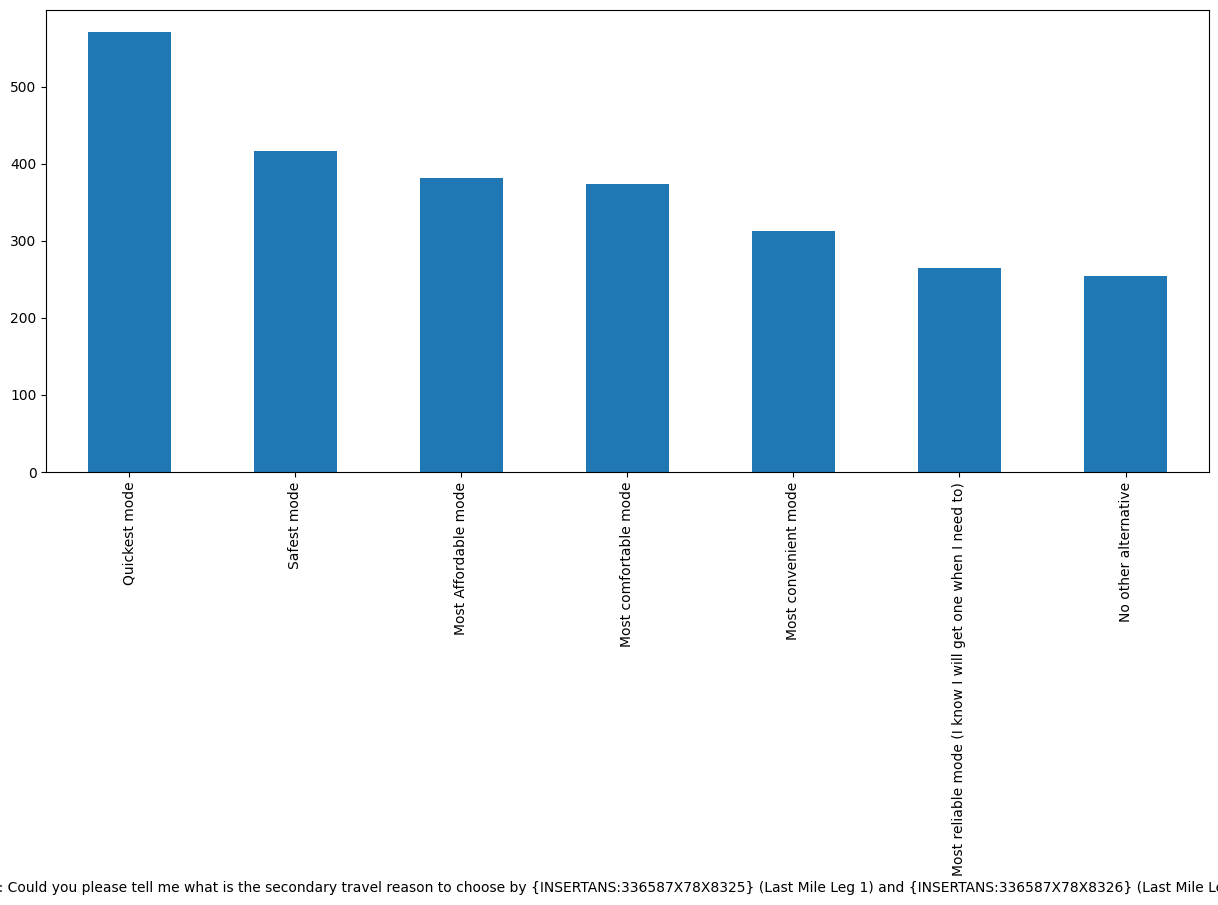

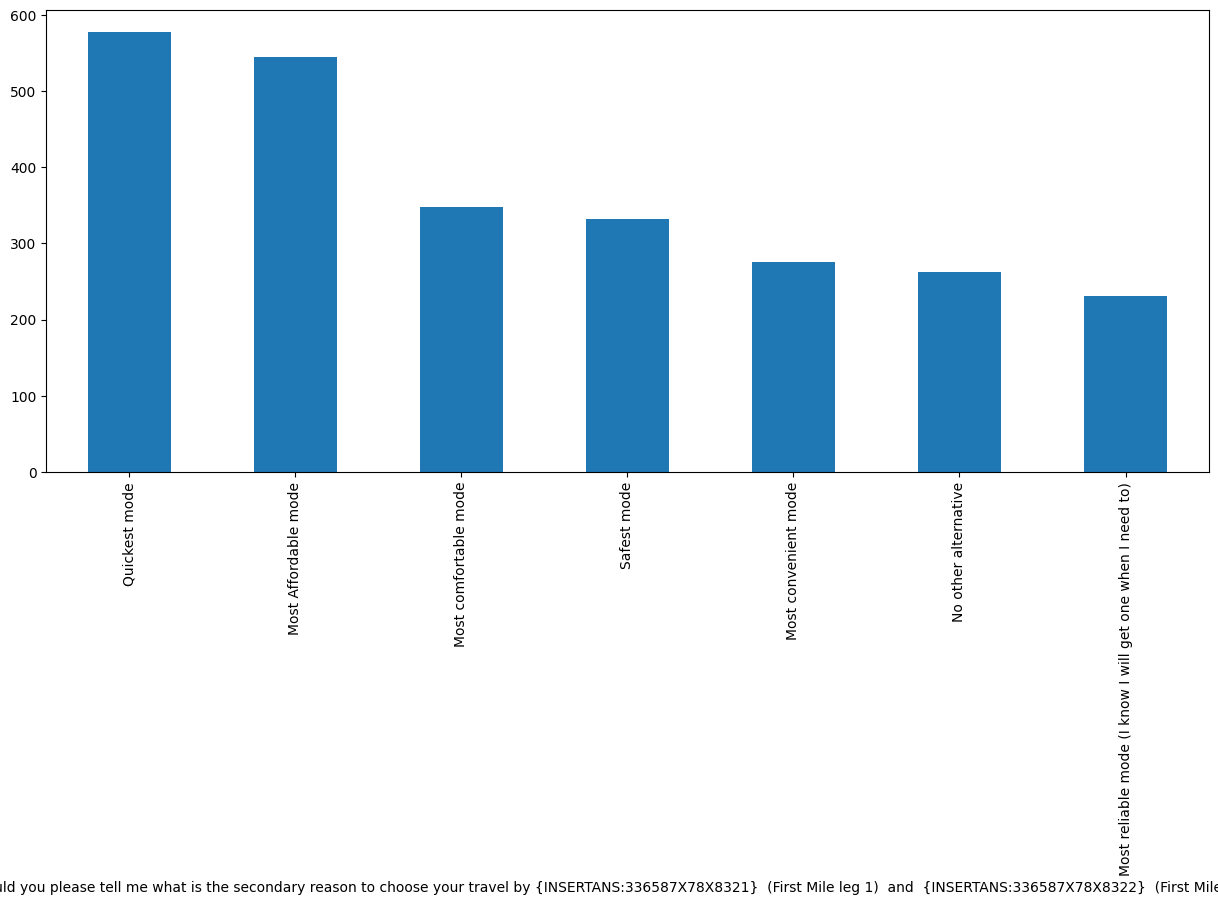

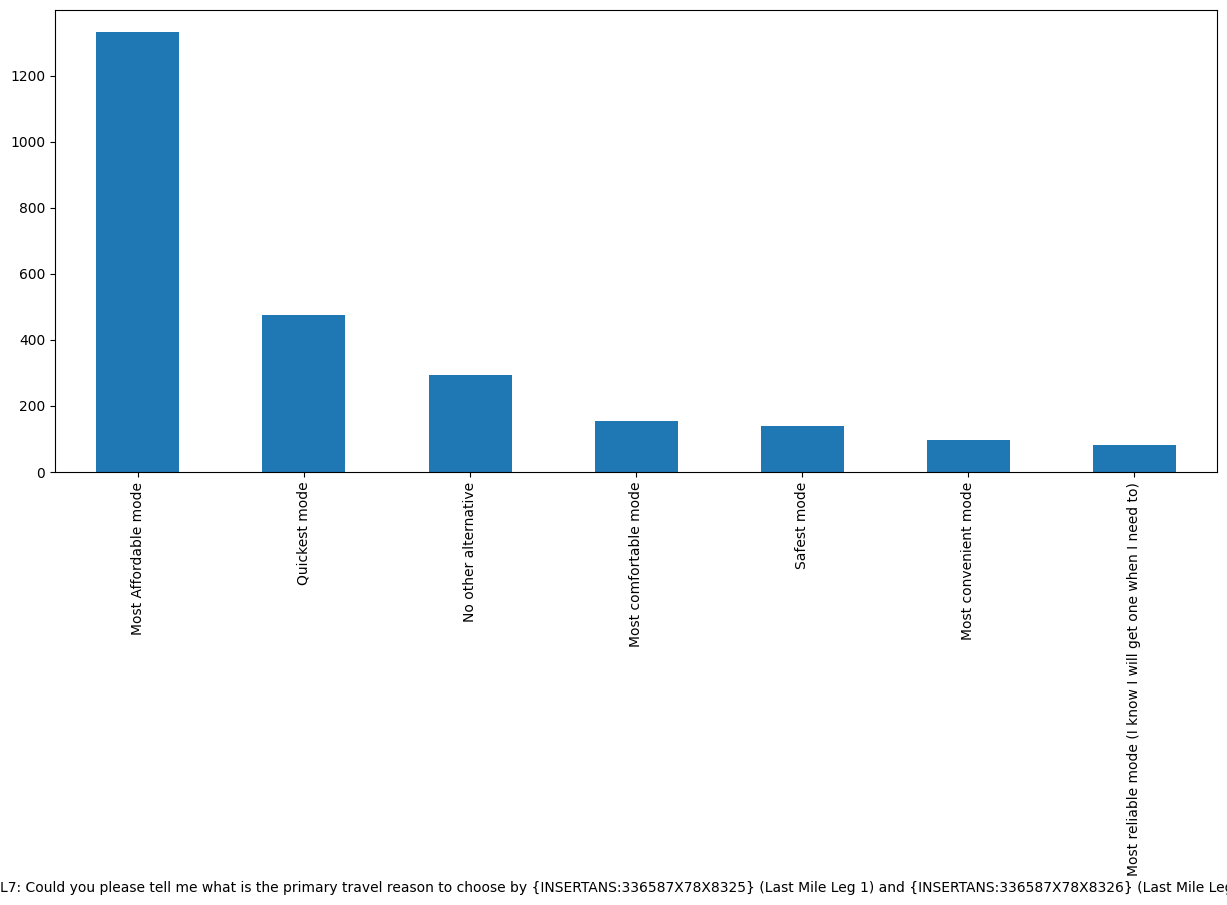

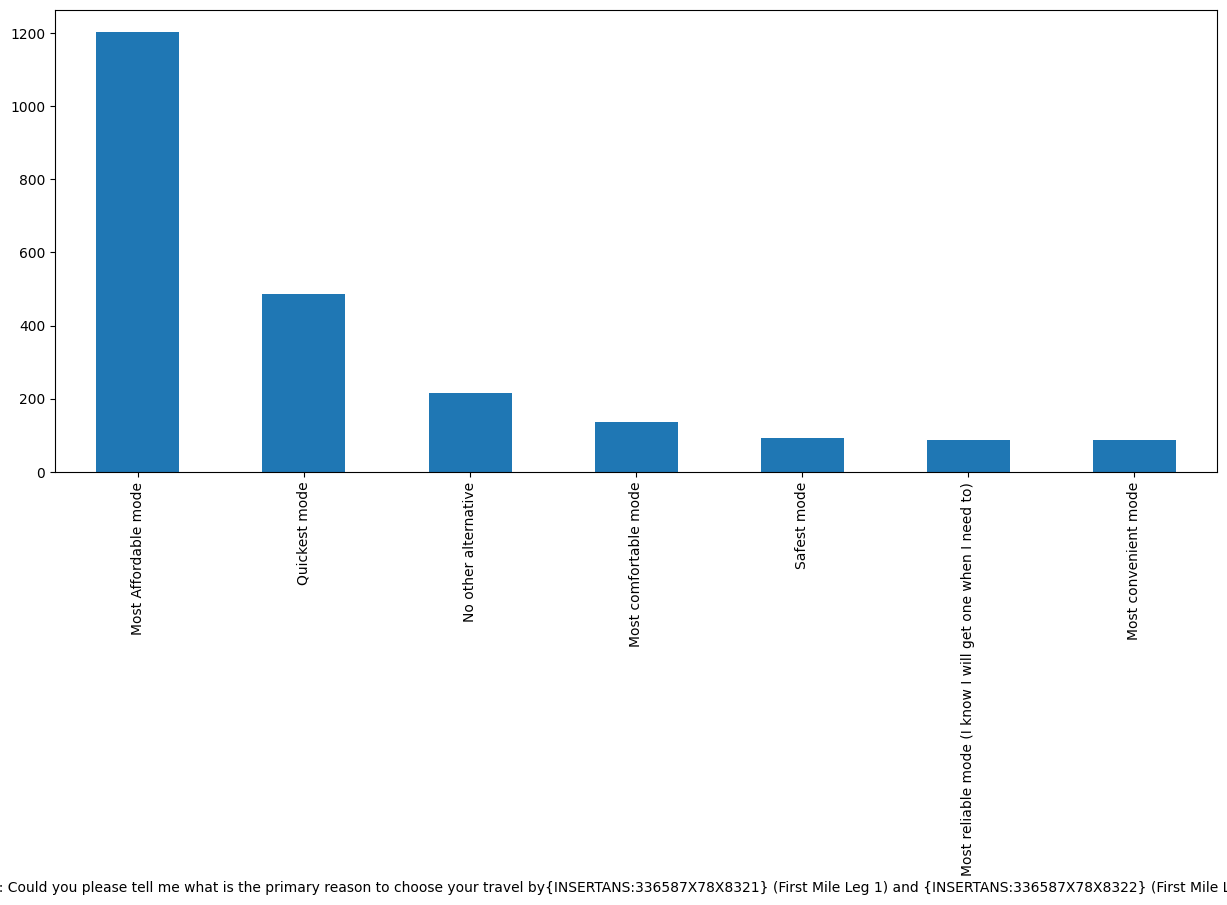

In [201]:
# Q7F9. Could you please tell me what is the primary reason to choose your travel by XXXXXX (First Mile Leg 1) and XXXXXX (First Mile Leg 2)?
column_name_reason_first_mile = "F7: Could you please tell me what is the primary reason to choose your travel by{INSERTANS:336587X78X8321} (First Mile Leg 1) and {INSERTANS:336587X78X8322} (First Mile Leg 2)?    "

# Q7F10. Could you please tell me what is the secondary reason to choose your travel by XXXXXX (First Mile leg 1) and XXXXXX (First Mile leg 2)?
column_name_secondary_reason_first_mile = "F8: Could you please tell me what is the secondary reason to choose your travel by {INSERTANS:336587X78X8321}  (First Mile leg 1)  and  {INSERTANS:336587X78X8322}  (First Mile leg 2)?       "

# Q7L9. Could you please tell me what is the primary travel reason to choose by XXXXXX (Last Mile Leg 1) and XXXXXX (Last Mile Leg 2)?
column_name_reason_last_mile = "L7: Could you please tell me what is the primary travel reason to choose by {INSERTANS:336587X78X8325} (Last Mile Leg 1) and {INSERTANS:336587X78X8326} (Last Mile Leg 2)?   "

# Q7L10. Could you please tell me what is the secondary travel reason to choose by XXXXXX (Last Mile leg 1) and XXXXXX (Last Mile leg 2)?
column_name_secondary_reason_last_mile = "L8: Could you please tell me what is the secondary travel reason to choose by {INSERTANS:336587X78X8325} (Last Mile Leg 1) and {INSERTANS:336587X78X8326} (Last Mile Leg 2)?   "

# Remove numbers only from 0 to 100
pattern = r'\b(?:[0-9]{1,2}|100)\b'

d[column_name_reason_first_mile] = d[column_name_reason_first_mile].str.replace(pattern, '', regex=True).str.strip()
d[column_name_reason_last_mile] = d[column_name_reason_last_mile].str.replace(pattern, '', regex=True).str.strip()
d[column_name_secondary_reason_last_mile] = d[column_name_secondary_reason_last_mile].str.replace(pattern, '', regex=True).str.strip()


# Value counts
print(d[column_name_secondary_reason_last_mile].value_counts())
print(d[column_name_secondary_reason_first_mile].value_counts())
print(d[column_name_reason_last_mile].value_counts())
print(d[column_name_reason_first_mile].value_counts())

# Graphical representation
plt.figure(figsize=(15,6))
d[column_name_secondary_reason_last_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_secondary_reason_first_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_reason_last_mile].value_counts().plot(kind='bar')
plt.figure(figsize=(15,6))
d[column_name_reason_first_mile].value_counts().plot(kind='bar')

In [202]:
# F1Time: How many minutes is your trip by {INSERTANS:336587X78X8321} ?
column_name_trip_time_first_mile_leg_1 = 'F1Time: How many minutes is your trip by {INSERTANS:336587X78X8321} ?'

null_values_trip_time_leg_1 = d[column_name_trip_time_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 1)': {null_values_trip_time_leg_1}")


# count values > 30
count_values_greater_30 = (d[column_name_trip_time_first_mile_leg_1] > 30).sum()
print(f"Number of values greater than 30 in 'Trip time by first mile connection (Leg 1)': {count_values_greater_30}")

# Drop values greater than 30
d = d[d[column_name_trip_time_first_mile_leg_1] <= 30]

print(d[column_name_trip_time_first_mile_leg_1].describe())
mean_first_mile_time = d[column_name_trip_time_first_mile_leg_1].mean()
print(f"Mean trip time by first mile connection (Leg 1): {mean_first_mile_time}")
median_first_mile_time = d[column_name_trip_time_first_mile_leg_1].median()
print(f"Median trip time by first mile connection (Leg 1): {median_first_mile_time}")
mode_first_mile_time = d[column_name_trip_time_first_mile_leg_1].mode()[0]
print(f"Mode trip time by first mile connection (Leg 1): {mode_first_mile_time}")
var_first_mile_time = d[column_name_trip_time_first_mile_leg_1].var()
print(f"Variance trip time by first mile connection (Leg 1): {var_first_mile_time}")

Number of null values in 'Trip time by first mile connection (Leg 1)': 0
Number of values greater than 30 in 'Trip time by first mile connection (Leg 1)': 14
count    2559.000000
mean       11.239937
std         5.771336
min         1.000000
25%         7.000000
50%        10.000000
75%        15.000000
max        30.000000
Name: F1Time: How many minutes is your trip by {INSERTANS:336587X78X8321} ?, dtype: float64
Mean trip time by first mile connection (Leg 1): 11.239937475576397
Median trip time by first mile connection (Leg 1): 10.0
Mode trip time by first mile connection (Leg 1): 10
Variance trip time by first mile connection (Leg 1): 33.30831836981864


In [203]:
# F4Time: How many minutes is your trip by {INSERTANS:336587X78X8322} ?

d1 = d.copy()

column_name_trip_time_First_mile_leg_2 = "F4Time: How many minutes is your trip by {INSERTANS:336587X78X8322} ?"
# Null values in trip time leg 2
null_values_trip_time_leg_2 = d1[column_name_trip_time_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 2)': {null_values_trip_time_leg_2}")

for index, row in d1.iterrows():
    if row[column_name_First_mile_leg_2] == "No First mile leg 2":
        d1.at[index, column_name_trip_time_First_mile_leg_2] = 0

null_values_trip_time_leg_2_after = d1[column_name_trip_time_First_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip time by first mile connection (Leg 2)' after filling: {null_values_trip_time_leg_2_after}")


print(d1[column_name_trip_time_First_mile_leg_2].describe())

# Values > 40 count
print(d1[d1[column_name_trip_time_First_mile_leg_2] > 40][column_name_trip_time_First_mile_leg_2].count())

# Drop values > 40
d1 = d1[d1[column_name_trip_time_First_mile_leg_2] <= 40]

print(d1[column_name_trip_time_First_mile_leg_2].describe())
mean_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].mean()
print(f"Mean of '{column_name_trip_time_First_mile_leg_2}': {mean_column_name_trip_time_First_mile_leg_2}")
median_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].median()
print(f"Median of '{column_name_trip_time_First_mile_leg_2}': {median_column_name_trip_time_First_mile_leg_2}")
mode_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].mode()[0]
print(f"Mode of '{column_name_trip_time_First_mile_leg_2}': {mode_column_name_trip_time_First_mile_leg_2}")
variance_column_name_trip_time_First_mile_leg_2 = d1[column_name_trip_time_First_mile_leg_2].var()
print(f"Variance of '{column_name_trip_time_First_mile_leg_2}': {variance_column_name_trip_time_First_mile_leg_2}")

Number of null values in 'Trip time by first mile connection (Leg 2)': 1514
Number of null values in 'Trip time by first mile connection (Leg 2)' after filling: 0
count    2559.000000
mean        8.216100
std        15.463613
min         0.000000
25%         0.000000
50%         0.000000
75%        15.000000
max       202.000000
Name: F4Time: How many minutes is your trip by {INSERTANS:336587X78X8322} ?, dtype: float64
66
count    2493.000000
mean        6.558363
std         9.513291
min         0.000000
25%         0.000000
50%         0.000000
75%        15.000000
max        40.000000
Name: F4Time: How many minutes is your trip by {INSERTANS:336587X78X8322} ?, dtype: float64
Mean of 'F4Time: How many minutes is your trip by {INSERTANS:336587X78X8322} ?': 6.558363417569193
Median of 'F4Time: How many minutes is your trip by {INSERTANS:336587X78X8322} ?': 0.0
Mode of 'F4Time: How many minutes is your trip by {INSERTANS:336587X78X8322} ?': 0.0
Variance of 'F4Time: How many minutes is yo

In [204]:
# Mode Share in First Mile Connectivity
d1['First Mile Mode Sharing'] = d1[column_name_first_mile_leg_1] + ' + ' + d1[column_name_First_mile_leg_2]

# Mode Share Trip Time in First Mile Connectivity
d1['First Mile Mode share Trip Time'] = d1[column_name_trip_time_first_mile_leg_1] + d1[column_name_trip_time_First_mile_leg_2]


In [205]:
# Q7F3.  How much do you pay for the trip by xxxx (mentioned automatically)? - First mile connection (Leg 1) - Trip Cost (In Rupees) :
column_name_trip_cost_first_mile_leg_1 = "F3: How far do you travel in terms of distance by  {INSERTANS:336587X78X8321}?(Insert 0 if not known)  Distance (in KM):"

# Null values in trip cost first mile leg 1
null_values_trip_cost_first_mile_leg_1 = d[column_name_trip_cost_first_mile_leg_1].isnull().sum()
print(f"Number of null values in 'Trip cost by first mile connection (Leg 1)': {null_values_trip_cost_first_mile_leg_1}")

print(d[column_name_trip_cost_first_mile_leg_1].describe())

# Count values >10 and <1
count_values_greater_10 = (d[column_name_trip_cost_first_mile_leg_1] > 10).sum()
count_values_less_1 = (d[column_name_trip_cost_first_mile_leg_1] < 1).sum()
print(f"Number of values greater than 10 in 'Trip cost by first mile connection (Leg 1)': {count_values_greater_10}")
print(f"Number of values less than 1 in 'Trip cost by first mile connection (Leg 1)': {count_values_less_1}")

# Remove values >10
d = d[d[column_name_trip_cost_first_mile_leg_1] <= 10]

print(d[column_name_trip_cost_first_mile_leg_1].describe())
mean_trip_cost_first_mile_leg_1 = d[column_name_trip_cost_first_mile_leg_1].mean()
print(f"Mean trip cost by first mile connection (Leg 1): {mean_trip_cost_first_mile_leg_1}")
median_trip_cost_first_mile_leg_1 = d[column_name_trip_cost_first_mile_leg_1].median()
print(f"Median trip cost by first mile connection (Leg 1): {median_trip_cost_first_mile_leg_1}")
mode_trip_cost_first_mile_leg_1 = d[column_name_trip_cost_first_mile_leg_1].mode()[0]
print(f"Mode trip cost by first mile connection (Leg 1): {mode_trip_cost_first_mile_leg_1}")
var_trip_cost_first_mile_leg_1 = d[column_name_trip_cost_first_mile_leg_1].var()
print(f"Variance trip cost by first mile connection (Leg 1): {var_trip_cost_first_mile_leg_1}")

Number of null values in 'Trip cost by first mile connection (Leg 1)': 0
count    2559.000000
mean        1.200469
std         1.628617
min         0.000000
25%         0.500000
50%         0.600000
75%         1.000000
max        20.000000
Name: F3: How far do you travel in terms of distance by  {INSERTANS:336587X78X8321}?(Insert 0 if not known)  Distance (in KM):, dtype: float64
Number of values greater than 10 in 'Trip cost by first mile connection (Leg 1)': 7
Number of values less than 1 in 'Trip cost by first mile connection (Leg 1)': 1400
count    2552.000000
mean        1.163793
std         1.460065
min         0.000000
25%         0.500000
50%         0.600000
75%         1.000000
max        10.000000
Name: F3: How far do you travel in terms of distance by  {INSERTANS:336587X78X8321}?(Insert 0 if not known)  Distance (in KM):, dtype: float64
Mean trip cost by first mile connection (Leg 1): 1.1637931034482758
Median trip cost by first mile connection (Leg 1): 0.6
Mode trip cost 

In [206]:
# F6: How far do you travel in terms of distance by  {INSERTANS:336587X78X8322}?   (Insert 0 if not known)  Distance (in KM):
column_name_trip_cost_first_mile_leg_2 = "F6: How far do you travel in terms of distance by  {INSERTANS:336587X78X8322}?   (Insert 0 if not known)  Distance (in KM):"
# Null values in trip cost first mile leg 2
null_values_trip_cost_first_mile_leg_2 = d1[column_name_trip_cost_first_mile_leg_2].isnull().sum()
print(f"Number of null values in 'Trip cost by first mile connection (Leg 2)': {null_values_trip_cost_first_mile_leg_2}")


for mode in d1[column_name_First_mile_leg_2].unique():
    if mode == "No First mile leg 2":
        d1.loc[d1[column_name_First_mile_leg_2] == mode, column_name_trip_cost_first_mile_leg_2] = 0


print(d1[column_name_trip_cost_first_mile_leg_2].describe())

# VValues >7 count
count_values_greater_10_leg_2 = (d1[column_name_trip_cost_first_mile_leg_2] > 7).sum()
print(f"Number of values greater than 10 in 'Trip cost by first mile connection (Leg 2)': {count_values_greater_10_leg_2}")

# Drop values > 7
d1 = d1[d1[column_name_trip_cost_first_mile_leg_2] <= 7]
print(d1[column_name_trip_cost_first_mile_leg_2].describe())
mean_trip_cost_first_mile_leg_2 = d1[column_name_trip_cost_first_mile_leg_2].mean()
print(f"Mean trip cost by first mile connection (Leg 2): {mean_trip_cost_first_mile_leg_2}")
median_trip_cost_first_mile_leg_2 = d1[column_name_trip_cost_first_mile_leg_2].median()
print(f"Median trip cost by first mile connection (Leg 2): {median_trip_cost_first_mile_leg_2}")
mode_trip_cost_first_mile_leg_2 = d1[column_name_trip_cost_first_mile_leg_2].mode()[0]
print(f"Mode trip cost by first mile connection (Leg 2): {mode_trip_cost_first_mile_leg_2}")
var_trip_cost_first_mile_leg_2 = d1[column_name_trip_cost_first_mile_leg_2].var()
print(f"Variance trip cost by first mile connection (Leg 2): {var_trip_cost_first_mile_leg_2}")

Number of null values in 'Trip cost by first mile connection (Leg 2)': 1514
count    2493.000000
mean        1.916735
std         4.214861
min         0.000000
25%         0.000000
50%         0.000000
75%         3.000000
max        80.000000
Name: F6: How far do you travel in terms of distance by  {INSERTANS:336587X78X8322}?   (Insert 0 if not known)  Distance (in KM):, dtype: float64
Number of values greater than 10 in 'Trip cost by first mile connection (Leg 2)': 174
count    2319.000000
mean        1.060552
std         1.893648
min         0.000000
25%         0.000000
50%         0.000000
75%         1.450000
max         7.000000
Name: F6: How far do you travel in terms of distance by  {INSERTANS:336587X78X8322}?   (Insert 0 if not known)  Distance (in KM):, dtype: float64
Mean trip cost by first mile connection (Leg 2): 1.060551962052609
Median trip cost by first mile connection (Leg 2): 0.0
Mode trip cost by first mile connection (Leg 2): 0.0
Variance trip cost by first mile co

In [208]:
d1['First Mile Leg 1 Mode share Distance'] = d1[column_name_trip_cost_first_mile_leg_1] + d1[column_name_trip_cost_first_mile_leg_2]
d1['Last Mile Mode Sharing'] = d1[column_name_last_mile_leg_1] + ' + ' + d1[column_name_last_mile_leg_2]



In [209]:
# Save the cleaned data to a new CSV file
d1.to_csv('cleaned_survey_data_nagpur.csv', index=False)

In [210]:
d1.columns

Index(['Respondent ID', 'Metro Station at which the survey is being conducted',
       'Location within station where survey is being conducted (example – entry gate/exit gate/platform).',
       'Which is the **Origin** metro station of this trip? / Which is the **Destination** metro station of this trip?',
       'Frequency of the trip', 'purpose of this trip',
       'When do you make the return ', 'First mile connection (Leg 1)',
       'First mile connection (Leg 2)', 'Primary Mode (Leg 1)',
       'Primary Mode (Leg 2)', 'Last Mile connection (Leg 1)',
       'Last Mile connection (Leg 2)',
       'F1Time: How many minutes is your trip by {INSERTANS:336587X78X8321} ?',
       'F2Cost: How much do you pay for the trip by {INSERTANS:336587X78X8321} ?  [Not applicable for walk trips. Insert 0 for personal bicycle]',
       'F3: How far do you travel in terms of distance by  {INSERTANS:336587X78X8321}?(Insert 0 if not known)  Distance (in KM):',
       'F4Time: How many minutes is yo